<p style="text-align: center;">
  <img src="https://github.com/digital-futures-academy/DataScienceMasterResources/blob/main/Resources/datascience-notebook-header.png?raw=true"
       alt="DigitalFuturesLogo"
       style="display: inline-block; margin: 0 auto;" />
</p>

# Frontier AI: Pandas Essentials Workbook

(V1) This notebook is a **mini reference of core Pandas skills**, using a small toy dataset so you can:
- See the pattern
- Copy/paste
- Adapt to your own projects

You don't need any external files — the data is created inside the notebook.

### Contents
1. Setup & Toy Dataset  
2. Inspecting DataFrames  
3. Selecting Rows & Columns  
4. Filtering Data  
5. Common Transformations (rename, sort, drop, new columns)  
6. Handling Missing Data  
7. GroupBy & Aggregation  
8. Pivoting & Reshaping  
9. Working with Dates & Times  
10. Merging / Joining DataFrames  
11. Basic Plotting  


---
## 1) Setup & Toy Dataset

We'll create a **toy sales dataset** with columns like:

- `order_id` — unique order ID  
- `customer` — customer name  
- `region` — sales region  
- `product` — product name  
- `quantity` — number of items  
- `unit_price` — price per item  
- `order_date` — date of the order  

Run the cell below to set everything up.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "order_id": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "customer": [
        "Amelia", "Mohammed", "Olivia", "Arjun", "Grace",
        "Aaliyah", "James", "Zara", "Luca", "Patrick"
    ],
    "region": [
        "London", "Scotland", "Wales", "North West", "South East",
        "Yorkshire", "Midlands", "South West", "Northern Ireland", "London"
    ],
    "product": [
        "Laptop", "Wireless Mouse", "Mechanical Keyboard", "Laptop",
        "4K Monitor", "4K Monitor", "Wireless Mouse", "Laptop",
        "Mechanical Keyboard", "Wireless Mouse"
    ],
    "quantity": [1, 2, 1, 3, 2, 1, 5, 2, 4, 3],
    "unit_price": [1000, 25, 45, 1000, 300, 320, 25, 950, 40, 25],
    "order_date": [
        "2024-01-01", "2024-01-03", "2024-01-05", "2024-01-05", "2024-01-07",
        "2024-01-09", "2024-01-10", "2024-01-11", "2024-01-13", "2024-01-15"
    ]
}

df = pd.DataFrame(data)

# Convert order_date to datetime
df['order_date'] = pd.to_datetime(df['order_date'])

df

,order_id,customer,region,product,quantity,unit_price,order_date
0,101,Amelia,London,Laptop,1,1000,2024-01-01
1,102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
2,103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05
3,104,Arjun,North West,Laptop,3,1000,2024-01-05
4,105,Grace,South East,4K Monitor,2,300,2024-01-07
5,106,Aaliyah,Yorkshire,4K Monitor,1,320,2024-01-09
6,107,James,Midlands,Wireless Mouse,5,25,2024-01-10
7,108,Zara,South West,Laptop,2,950,2024-01-11
8,109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13
9,110,Patrick,London,Wireless Mouse,3,25,2024-01-15


---
## 2) Inspecting DataFrames

Some of the **most important commands** when you first meet a dataset:

- `df.head()` — first 5 rows  
- `df.tail()` — last 5 rows  
- `df.shape` — number of rows and columns  
- `df.info()` — data types + non-null counts  
- `df.describe()` — summary statistics for numeric columns  
- `df.sample(n)` — random sample of rows  


Show the first 5 rows

In [2]:
df.head()

,order_id,customer,region,product,quantity,unit_price,order_date
0,101,Amelia,London,Laptop,1,1000,2024-01-01
1,102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
2,103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05
3,104,Arjun,North West,Laptop,3,1000,2024-01-05
4,105,Grace,South East,4K Monitor,2,300,2024-01-07


Show the last 3 rows

In [3]:
df.tail(3)

,order_id,customer,region,product,quantity,unit_price,order_date
7,108,Zara,South West,Laptop,2,950,2024-01-11
8,109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13
9,110,Patrick,London,Wireless Mouse,3,25,2024-01-15


Inspect the shape (rows, columns) - Note that this one is an attribute not a method!

In [4]:
df.shape

(10, 7)

Find the info - Data types and non-null counts

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   order_id    10 non-null     int64         
 1   customer    10 non-null     str           
 2   region      10 non-null     str           
 3   product     10 non-null     str           
 4   quantity    10 non-null     int64         
 5   unit_price  10 non-null     int64         
 6   order_date  10 non-null     datetime64[us]
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 955.0 bytes


Summary statistics for numeric columns

In [6]:
df.describe()

,order_id,quantity,unit_price,order_date
count,10.00000,10.000000,10.000000,10
mean,105.50000,2.400000,373.000000,2024-01-07 21:36:00
min,101.00000,1.000000,25.000000,2024-01-01 00:00:00
25%,103.25000,1.250000,28.750000,2024-01-05 00:00:00
50%,105.50000,2.000000,172.500000,2024-01-08 00:00:00
75%,107.75000,3.000000,792.500000,2024-01-10 18:00:00
max,110.00000,5.000000,1000.000000,2024-01-15 00:00:00
std,3.02765,1.349897,435.776446,NaN


**Practice:** Get summary statistics for ALL columns (try using describe but set the argument `include` to `"all"`)

In [7]:
df.describe(include = "all")

,order_id,customer,region,product,quantity,unit_price,order_date
count,10.00000,10,10,10,10.000000,10.000000,10
unique,NaN,10,9,4,NaN,NaN,NaN
top,NaN,Amelia,London,Laptop,NaN,NaN,NaN
freq,NaN,1,2,3,NaN,NaN,NaN
mean,105.50000,NaN,NaN,NaN,2.400000,373.000000,2024-01-07 21:36:00
min,101.00000,NaN,NaN,NaN,1.000000,25.000000,2024-01-01 00:00:00
25%,103.25000,NaN,NaN,NaN,1.250000,28.750000,2024-01-05 00:00:00
50%,105.50000,NaN,NaN,NaN,2.000000,172.500000,2024-01-08 00:00:00
75%,107.75000,NaN,NaN,NaN,3.000000,792.500000,2024-01-10 18:00:00
max,110.00000,NaN,NaN,NaN,5.000000,1000.000000,2024-01-15 00:00:00


**Practice:** Get a random sample of 4 rows, use a `random_state` of 124

In [8]:
df.sample(n=4, random_state=124)

,order_id,customer,region,product,quantity,unit_price,order_date
6,107,James,Midlands,Wireless Mouse,5,25,2024-01-10
8,109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13
3,104,Arjun,North West,Laptop,3,1000,2024-01-05
5,106,Aaliyah,Yorkshire,4K Monitor,1,320,2024-01-09


---
## 3) Selecting Rows & Columns

### Selecting columns
- Single column: `df['column']` → Series  
- Multiple columns: `df[['col1', 'col2']]` → DataFrame  

### Selecting rows by position: `.iloc`
- First row: `df.iloc[0]`  
- First 3 rows: `df.iloc[:3]`  

### Selecting rows by label: `.loc`
- Row with index label 101: `df.loc[101]` (after we set an index)  

We'll also set `order_id` as the index to see how `.loc` works nicely.


**Practice:** Select the customer name column and display it

In [9]:
customer_series = df['customer']
customer_series

0      Amelia
1    Mohammed
2      Olivia
3       Arjun
4       Grace
5     Aaliyah
6       James
7        Zara
8        Luca
9     Patrick
Name: customer, dtype: str

**Practice:** Select customer, region and product and display the first 5 rows

In [10]:
df[['customer', 'region', 'product']].head()

,customer,region,product
0,Amelia,London,Laptop
1,Mohammed,Scotland,Wireless Mouse
2,Olivia,Wales,Mechanical Keyboard
3,Arjun,North West,Laptop
4,Grace,South East,4K Monitor


Select just row 0 with `.iloc[]` (returns a Series)

In [11]:
first_row = df.iloc[0]
first_row

order_id                      101
customer                   Amelia
region                     London
product                    Laptop
quantity                        1
unit_price                   1000
order_date    2024-01-01 00:00:00
Name: 0, dtype: object

**Practice:** Select the first three rows with `.iloc[]` (returns a DataFrame)

In [12]:
first_3_rows = df.iloc[:3]
first_3_rows

,order_id,customer,region,product,quantity,unit_price,order_date
0,101,Amelia,London,Laptop,1,1000,2024-01-01
1,102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
2,103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05


Set `order_id` as index so we can use `.loc`

In [13]:
df = df.set_index('order_id')

In [14]:
df

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01
102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05
104,Arjun,North West,Laptop,3,1000,2024-01-05
105,Grace,South East,4K Monitor,2,300,2024-01-07
106,Aaliyah,Yorkshire,4K Monitor,1,320,2024-01-09
107,James,Midlands,Wireless Mouse,5,25,2024-01-10
108,Zara,South West,Laptop,2,950,2024-01-11
109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13


**Practice:** Select order 103 using `.loc`

In [15]:
df.loc[103]

customer                   Olivia
region                      Wales
product       Mechanical Keyboard
quantity                        1
unit_price                     45
order_date    2024-01-05 00:00:00
Name: 103, dtype: object

**Practice:** Select orders 101 to 104, and the customer, product and quantity columns

In [16]:
df.loc[101:104, ['customer', 'product', 'quantity']]

,customer,product,quantity
order_id,,,
101,Amelia,Laptop,1
102,Mohammed,Wireless Mouse,2
103,Olivia,Mechanical Keyboard,1
104,Arjun,Laptop,3


---
## 4) Filtering Data

Filtering, or selecting certain rows is one of the **most common things** you'll do. It's similar to a where clause in SQL.

The way it works in Pandas is interesting - we use a Boolean mask.

Pattern:
```python
mask = df['column'] <condition>
df_filtered = df[mask]
```

We can combine conditions with:
- `&`  (AND)  
- `|`  (OR)  
- `~`  (NOT)  


Select all orders from the 'London' region

In [17]:
lnd_mask = df['region'] == 'London'
lnd_mask

order_id
101     True
102    False
103    False
104    False
105    False
106    False
107    False
108    False
109    False
110     True
Name: region, dtype: bool

In [18]:
df[lnd_mask]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


In [19]:
# doing it all in one line
df[df['region'] == 'London']

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


**Practice:** Select all of the Orders where quantity >= 3

In [20]:
df[df['quantity'] >=3]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
104,Arjun,North West,Laptop,3,1000,2024-01-05
107,James,Midlands,Wireless Mouse,5,25,2024-01-10
109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


**Practice:** Find any Orders from South East, South West, or London

In [21]:
df[(df['region'] == 'South West') | (df['region'] == 'South East') | (df['region'] == 'London')]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01
105,Grace,South East,4K Monitor,2,300,2024-01-07
108,Zara,South West,Laptop,2,950,2024-01-11
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


In [22]:
df[df['region'].isin(['London', 'South East', 'South West'])]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01
105,Grace,South East,4K Monitor,2,300,2024-01-07
108,Zara,South West,Laptop,2,950,2024-01-11
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


**Practice:** Find any orders that are NOT from London

In [23]:
df[(df['region'] != 'London')]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05
104,Arjun,North West,Laptop,3,1000,2024-01-05
105,Grace,South East,4K Monitor,2,300,2024-01-07
106,Aaliyah,Yorkshire,4K Monitor,1,320,2024-01-09
107,James,Midlands,Wireless Mouse,5,25,2024-01-10
108,Zara,South West,Laptop,2,950,2024-01-11
109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13


Using `isin` for multiple matches - find orders for "Wireless Mouse" or "Mechanical Keyboard"

In [24]:
df[df['product'].isin(['Wireless Mouse', 'Mechanical Keyboard'])]

,customer,region,product,quantity,unit_price,order_date
order_id,,,,,,
102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03
103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05
107,James,Midlands,Wireless Mouse,5,25,2024-01-10
109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13
110,Patrick,London,Wireless Mouse,3,25,2024-01-15


---
## 5) Common Transformations

Key patterns:

- **Creating new columns**
  ```python
  df['new_col'] = ...
  ```

- **Renaming columns**
  ```python
  df.rename(columns={'old': 'new'}, inplace=True)
  ```

- **Sorting**
  ```python
  df.sort_values('column', ascending=False)
  ```

- **Dropping columns**
  ```python
  df.drop(columns=['col1', 'col2'])
  ```


**Practice:** Create a `total_value` column = quantity * unit_price

In [25]:
df['total_value'] = df['quantity'] * df['unit_price']
df


,customer,region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01,1000
102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03,50
103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05,45
104,Arjun,North West,Laptop,3,1000,2024-01-05,3000
105,Grace,South East,4K Monitor,2,300,2024-01-07,600
106,Aaliyah,Yorkshire,4K Monitor,1,320,2024-01-09,320
107,James,Midlands,Wireless Mouse,5,25,2024-01-10,125
108,Zara,South West,Laptop,2,950,2024-01-11,1900
109,Luca,Northern Ireland,Mechanical Keyboard,4,40,2024-01-13,160


Rename `region` → `sales_region`

In [26]:
df = df.rename(columns={'region': 'sales_region'})
df.head()

,customer,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
101,Amelia,London,Laptop,1,1000,2024-01-01,1000
102,Mohammed,Scotland,Wireless Mouse,2,25,2024-01-03,50
103,Olivia,Wales,Mechanical Keyboard,1,45,2024-01-05,45
104,Arjun,North West,Laptop,3,1000,2024-01-05,3000
105,Grace,South East,4K Monitor,2,300,2024-01-07,600


**Practice:** Sort by `total_value`, biggest first

In [27]:
df_sorted = df.sort_values('total_value', ascending=False)
df_sorted[['customer', 'product', 'total_value']].head()

,customer,product,total_value
order_id,,,
104,Arjun,Laptop,3000
108,Zara,Laptop,1900
101,Amelia,Laptop,1000
105,Grace,4K Monitor,600
106,Aaliyah,4K Monitor,320


**Practice:** Create a dataframe called `anon` that contains everything except the customer column

In [28]:
anon = df.drop(columns=['customer'])
anon.head()

,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,
101,London,Laptop,1,1000,2024-01-01,1000
102,Scotland,Wireless Mouse,2,25,2024-01-03,50
103,Wales,Mechanical Keyboard,1,45,2024-01-05,45
104,North West,Laptop,3,1000,2024-01-05,3000
105,South East,4K Monitor,2,300,2024-01-07,600


---
## 6) Handling Missing Data

Key methods:

- `df.isna()` — True/False for missing values  
- `df.isna().sum()` — count missing per column  
- `df.dropna()` — drop rows with missing values  
- `df.fillna(value)` — fill missing values  

We'll first create a small version with some missing values.


Create a small version with missing values

In [29]:
df_na = df.copy()
df_na.loc[101, 'unit_price'] = np.nan
df_na.loc[105, 'customer'] = np.nan

df_na

,customer,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
101,Amelia,London,Laptop,1,NaN,2024-01-01,1000
102,Mohammed,Scotland,Wireless Mouse,2,25.0,2024-01-03,50
103,Olivia,Wales,Mechanical Keyboard,1,45.0,2024-01-05,45
104,Arjun,North West,Laptop,3,1000.0,2024-01-05,3000
105,NaN,South East,4K Monitor,2,300.0,2024-01-07,600
106,Aaliyah,Yorkshire,4K Monitor,1,320.0,2024-01-09,320
107,James,Midlands,Wireless Mouse,5,25.0,2024-01-10,125
108,Zara,South West,Laptop,2,950.0,2024-01-11,1900
109,Luca,Northern Ireland,Mechanical Keyboard,4,40.0,2024-01-13,160


Where are the missing values?

In [30]:
df_na.isna()

,customer,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
101,False,False,False,False,True,False,False
102,False,False,False,False,False,False,False
103,False,False,False,False,False,False,False
104,False,False,False,False,False,False,False
105,True,False,False,False,False,False,False
106,False,False,False,False,False,False,False
107,False,False,False,False,False,False,False
108,False,False,False,False,False,False,False
109,False,False,False,False,False,False,False


**Practice:** Count missing values per column

In [31]:
df_na.isna().sum()

customer        1
sales_region    0
product         0
quantity        0
unit_price      1
order_date      0
total_value     0
dtype: int64

**Practice:** Fill missing `unit_price` with the mean unit_price

In [32]:
mean_price = df_na['unit_price'].mean()
df_filled = df_na.copy()
df_filled['unit_price'] = df_filled['unit_price'].fillna(mean_price)
df_filled

,customer,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
101,Amelia,London,Laptop,1,303.333333,2024-01-01,1000
102,Mohammed,Scotland,Wireless Mouse,2,25.000000,2024-01-03,50
103,Olivia,Wales,Mechanical Keyboard,1,45.000000,2024-01-05,45
104,Arjun,North West,Laptop,3,1000.000000,2024-01-05,3000
105,NaN,South East,4K Monitor,2,300.000000,2024-01-07,600
106,Aaliyah,Yorkshire,4K Monitor,1,320.000000,2024-01-09,320
107,James,Midlands,Wireless Mouse,5,25.000000,2024-01-10,125
108,Zara,South West,Laptop,2,950.000000,2024-01-11,1900
109,Luca,Northern Ireland,Mechanical Keyboard,4,40.000000,2024-01-13,160


**Practice:** Drop rows with ANY missing values

In [33]:
df_dropna = df_na.dropna()
df_dropna

,customer,sales_region,product,quantity,unit_price,order_date,total_value
order_id,,,,,,,
102,Mohammed,Scotland,Wireless Mouse,2,25.0,2024-01-03,50
103,Olivia,Wales,Mechanical Keyboard,1,45.0,2024-01-05,45
104,Arjun,North West,Laptop,3,1000.0,2024-01-05,3000
106,Aaliyah,Yorkshire,4K Monitor,1,320.0,2024-01-09,320
107,James,Midlands,Wireless Mouse,5,25.0,2024-01-10,125
108,Zara,South West,Laptop,2,950.0,2024-01-11,1900
109,Luca,Northern Ireland,Mechanical Keyboard,4,40.0,2024-01-13,160
110,Patrick,London,Wireless Mouse,3,25.0,2024-01-15,75


## Visualisation

<Axes: xlabel='order_id'>

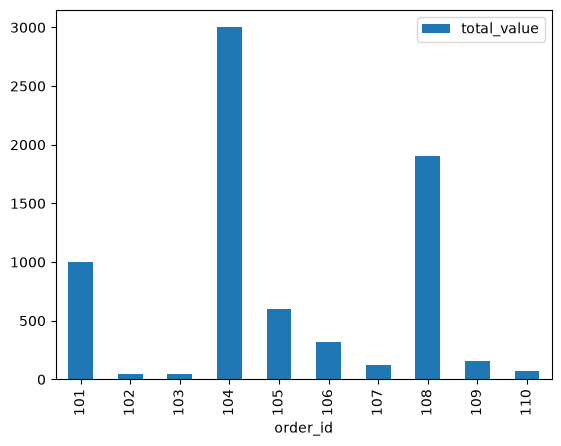

In [50]:
df[['total_value']].plot(kind = 'bar')

<Axes: >

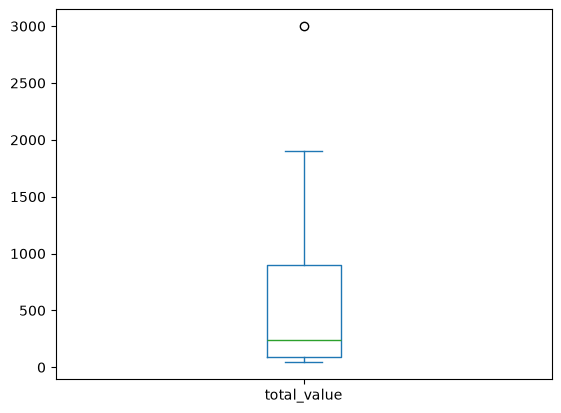

In [51]:
df[['total_value']].plot(kind = 'box')

---
## 7) GroupBy & Aggregation

Pattern:

```python
df.groupby('column')['other_column'].agg(['sum', 'mean', 'count'])
```

Useful for:
- Total sales per customer
- Average order value per region
- Number of orders per product


**Practice:** Find the total quantity per customer (i.e. sum of quantity per customer)

In [52]:
qty_per_customer = df.groupby('customer')['quantity'].sum()
qty_per_customer

customer
Aaliyah     1
Amelia      1
Arjun       3
Grace       2
James       5
Luca        4
Mohammed    2
Olivia      1
Patrick     3
Zara        2
Name: quantity, dtype: int64

**Practice:** Find the total sales value per customer (i.e. sum the `total_value` column for each customer)

In [53]:
sales_per_customer = df.groupby('customer')['total_value'].sum()
sales_per_customer

customer
Aaliyah      320
Amelia      1000
Arjun       3000
Grace        600
James        125
Luca         160
Mohammed      50
Olivia        45
Patrick       75
Zara        1900
Name: total_value, dtype: int64

**Practice:** Multiple aggregations per customer - find the sum, mean and count of `total_value`

In [54]:
customer_stats = df.groupby('customer')['total_value'].agg(['sum', 'mean', 'count'])
customer_stats

,sum,mean,count
customer,,,
Aaliyah,320,320.0,1
Amelia,1000,1000.0,1
Arjun,3000,3000.0,1
Grace,600,600.0,1
James,125,125.0,1
Luca,160,160.0,1
Mohammed,50,50.0,1
Olivia,45,45.0,1
Patrick,75,75.0,1


**Practice:** Group by two columns: `sales_region` and `product` and find the sum of `total_value`

In [56]:
region_product_stats = df.groupby(['sales_region', 'product'])['total_value'].agg(['sum'])
region_product_stats

sum
sales_region     product                  
London           Laptop               1000
                 Wireless Mouse         75
Midlands         Wireless Mouse        125
North West       Laptop               3000
Northern Ireland Mechanical Keyboard   160
Scotland         Wireless Mouse         50
South East       4K Monitor            600
South West       Laptop               1900
Wales            Mechanical Keyboard    45
Yorkshire        4K Monitor            320

---
## 8) Pivoting & Reshaping

### `pivot_table`
Turn "long" data into a table with rows and columns.

```python
pd.pivot_table(df, values='total_value', index='sales_region', columns='product', aggfunc='sum')
```

### `melt`
Go from wide → long.

```python
df_long = df.melt(id_vars=[...], value_vars=[...])
```


**Practice:** Create a pivot table of the data.
- The value should be `total_value`
- The index should be `sales_region`
- The columns should be `product`
- The aggfunc should be `sum`
- Fill any missing values with 0

In [38]:
# YOUR CODE HERE

---
# 9) Working with Dates & Times

We already converted `order_date` to datetime.

Useful patterns:

- Extract parts:
  ```python
  df['order_date'].dt.year
  df['order_date'].dt.month
  df['order_date'].dt.day_name()
  ```

- Resample (needs a DateTimeIndex):
  ```python
  df.set_index('order_date').resample('D').sum()
  ```


**Practice:** Extract year, month, day name into new columns called `year`, `month`, `day_name`

In [39]:
# YOUR CODE HERE

**Practice:** Create a date index. Then create a new dataframe called `daily_sales` that is resampled to a daily frequency and sums the `total_value` column

In [40]:
# YOUR CODE HERE

---
## 10) Merging / Joining DataFrames

Very common pattern when data comes from multiple tables.

Pattern:

```python
pd.merge(left_df, right_df, on='key_column', how='left')
```

We'll create a small **customers table** and merge it with the orders.


Customers table with extra info

In [41]:
# YOUR CODE HERE

**Practice:** Merge the new customers table into the original df. Merge on `customer`, with a left join.

In [42]:
# YOUR CODE HERE

# In the next workshops, We'll learn how to make graphs in Matplotlib and Seaborn!